# PW5 - Linear Regression

## Imports

In [20]:
import random
import pandas as pd
import numpy as np
from numpy.linalg import inv
import matplotlib.pyplot as plt

## Load data

Define the path to the file containing the data

In [21]:
datafile = "lausanne-appart.csv"

Read the data

In [22]:
dataset = pd.read_csv(datafile)

Display first rows

In [23]:
dataset.head()

,living_area,nb_rooms,rent_price
0,69,3.0,1810
1,95,3.5,2945
2,21,1.5,685
3,20,1.0,720
4,33,1.5,830


## Exercise 1 - Visualize the data

a) Plot a histogram to visualize the distribution of the renting price

In [24]:
# Your code here

b) Plot a histogram to visualize the distribution of the living area

In [25]:
# Your code here

c) Plot a scatter plot of renting price as a function of living area

In [26]:
# Your code here

## Exercise 2 - Normal equations for linear regression

a) Implement the closed form solution to this problem using the following normal equation:

$\theta = (X^{T}X)^{-1}X^{T}\vec{y}$

$(3)$

Assuming $x$ is the living area and $y$ is the renting price. Use `numpy` for the vector operations. Plot the computed line on top of the scatter plot of exercise 1.

In [27]:
# Your code here

b) Compute the overall cost value according to the following equation:

$J(\theta) = \frac{1}{2N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n})^{2}$

$(2)$

In [28]:
# Your code here

c) The cost value reflects the performance of your system. Is this cost value *readable* for a client of your system ? What other metric could we use to make it more readable to the client ? Optional: implement it.

_Your answer here_

## Exercise 3 - Gradient descent for linear regression

Implement the _full batch_ gradient descent algorithm for the previous problem. As seen in the
theory, the update rules are:

$\theta_{0} \leftarrow \theta_{0} - \alpha \frac{1}{N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n})$

$(6)$

$\theta_{1} \leftarrow \theta_{1} - \alpha \frac{1}{N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n}) x_{n,1}$

$(7)$

**Remark** You need to iterate several times over the training set. If you have problems of convergence, you need to use a smaller value of $\alpha$. Values such as $0.000001$ are common.

In [29]:
# Your code here

a) Plot the cost value (Equation 2) as a function of the iterations. What do you observe?

In [30]:
# Your code here

_Your answer here_

b) Imagine a stopping criterion, i.e. when do we stop iterating on the training set?

_Your answer here_

c) Plot the computed line $h_{\theta}(\mathbf{x})$ on top of the scatter plot of exercise 1.

In [31]:
# Your code here

d) Compute the final cost value according to Equation 2 and compare it to the one of exercise 2. What can you conclude?

In [32]:
# Your code here

_Your answer here_

## Exercise 4 - Stochastic gradient descent for linear regression

Implement the stochastic gradient descent algorithm for the previous problem. As seen in the theory, the update rules are:

$\theta_{i} \leftarrow \theta_{i} - \alpha (h_{\theta}(\mathbf{x}_{n}) - y_{n}) x_{n,i}$

$(8)$

In [33]:
X = dataset.living_area.values
y = dataset.rent_price.values

In [34]:
def stochastic_gradient_descent(X, y, verbose=True):
    N = len(X)

    # randomly initialize thetas
    theta_0 = random.uniform(0.0, float(y.max())) # y interceot
    theta_1 = random.uniform(-1.0, 1.0) # slope

    print(f"Initial random values for theta_0 (y intercept) {theta_0:.4f} and theta_1 (slope) {theta_1:.4f}")
    
    x_mean, x_std = X.mean(), X.std()
    x_norm = (X - x_mean) / x_std

    # Training parameters
    max_iters = 200_000
    check_every = 1000
    tolerance = 1e-3
    prev_loss = None
    alpha = 0.0001

    # History used for animations
    history = [] # (iteration, intercept, slope) in original units
    history.append((0, theta_0 - theta_1 * x_mean / x_std, theta_1 / x_std))
    record_every = 50

    for it in range(1, max_iters + 1):
        sample_n = random.randrange(0, N)
        x_n = x_norm[sample_n]
        y_n = y[sample_n]

        error = (theta_0 + theta_1 * x_n) - y_n
        theta_0 -= alpha * error
        theta_1 -= alpha * error * x_n

        if it % record_every == 0:
            history.append((it, theta_0 - theta_1 * x_mean / x_std, theta_1 / x_std))

        if it % check_every == 0:
            loss = np.mean((theta_0 + theta_1 * x_norm - y) ** 2) / 2
            if verbose:
                print(f"iter {it}: loss = {loss:.2f}, theta_0 = {theta_0:.3f}, theta_1 = {theta_1:.3f}")

            if not np.isfinite(loss):
                print("Diverged: try a smaller alpha")
                break
            if prev_loss is not None and abs(prev_loss - loss) < tolerance * prev_loss:
                print("Converged")
                break
            prev_loss = loss

    intercept = theta_0 - theta_1 * x_mean / x_std
    slope = theta_1 / x_std
    return history, intercept, slope

In [35]:
history, intercept, slope = stochastic_gradient_descent(X, y)

Initial random values for theta_0 (y intercept) 1477.7911 and theta_1 (slope) -0.9731
iter 1000: loss = 964830.93, theta_0 = 1569.265, theta_1 = 113.094
iter 2000: loss = 813244.69, theta_0 = 1645.450, theta_1 = 210.762
iter 3000: loss = 701710.54, theta_0 = 1712.438, theta_1 = 285.591
iter 4000: loss = 598525.38, theta_0 = 1775.938, theta_1 = 365.533
iter 5000: loss = 512575.68, theta_0 = 1833.500, theta_1 = 440.108
iter 6000: loss = 445421.57, theta_0 = 1885.114, theta_1 = 503.079
iter 7000: loss = 388691.39, theta_0 = 1934.468, theta_1 = 560.964
iter 8000: loss = 344187.76, theta_0 = 1975.572, theta_1 = 612.506
iter 9000: loss = 304351.95, theta_0 = 2015.234, theta_1 = 664.495
iter 10000: loss = 273095.27, theta_0 = 2052.006, theta_1 = 708.081
iter 11000: loss = 247991.01, theta_0 = 2083.735, theta_1 = 747.733
iter 12000: loss = 229077.95, theta_0 = 2110.428, theta_1 = 780.461
iter 13000: loss = 213719.48, theta_0 = 2134.864, theta_1 = 809.128
iter 14000: loss = 199636.95, theta_0 =

a) Plot the computed line $h_{\theta}(\mathbf{x})$ on top of the scatter plot of exercise 1.

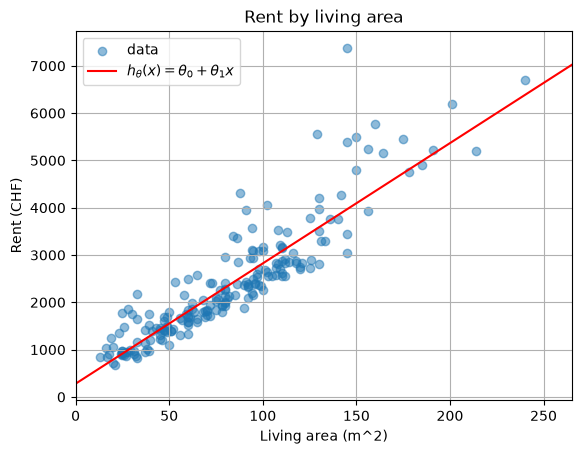

In [36]:
# Your code here
def line_on_scatter(X, y, intercept, slope):
    plt.title("Rent by living area")
    plt.xlabel("Living area (m^2)")
    plt.ylabel("Rent (CHF)")
    plt.scatter(X, y, alpha=0.5, label="data")

    # h_theta(x) = theta_0 + theta_1 * x
    x_line = np.array([0.0, X.max() + 25])
    y_line = intercept + slope * x_line
    plt.plot(x_line, y_line, color="red", label=r"$h_{\theta}(x) = {\theta}_0 + {\theta}_1x$")

    plt.xlim(0.0, X.max() + 25)
    plt.legend()
    plt.grid(True)
    plt.show()

line_on_scatter(X, y, intercept, slope)

Animation of SGD converging (made by Claude)

In [37]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

def animate_line_on_scatter(history, X, y, name):
    hist = np.array(history)   # columns: iteration, intercept, slope

    # Pick ~150 frames, spaced logarithmically so the fast early movement is visible
    idx = np.unique(np.geomspace(1, len(hist), 150).astype(int)) - 1

    x_line = np.array([0.0, X.max() + 25])

    fig, ax = plt.subplots()
    ax.scatter(X, y, alpha=0.5, label="data")
    slope_ref, intercept_ref = np.polyfit(X, y, 1)
    ax.plot(x_line, intercept_ref + slope_ref * x_line, "k--", lw=1, label="exact fit (polyfit)")
    line, = ax.plot([], [], color="red", lw=2, label=r"$h_{\theta}(x)$")
    text = ax.text(0.97, 0.05, "", transform=ax.transAxes, ha="right")

    ax.set_xlim(0.0, X.max() + 25)
    ax.set_ylim(0, y.max() * 1.1)
    ax.set_title("Rent by living area")
    ax.set_xlabel("Living area (m^2)")
    ax.set_ylabel("Rent (CHF)")
    ax.grid(True)
    ax.legend(loc="upper left")

    def update(frame):
        it, b, w = hist[idx[frame]]
        line.set_data(x_line, b + w * x_line)
        text.set_text(f"iteration {int(it)}")
        return line, text

    anim = FuncAnimation(fig, update, frames=len(idx), interval=50, blit=True)
    plt.close(fig)   # stops Jupyter from also showing a static copy

    HTML(anim.to_jshtml())
    anim.save(name, writer=PillowWriter(fps=20))

animate_line_on_scatter(history, X, y, "stochastic_gradient_descent.gif")

b) How many samples do you need to visit for reaching the convergence?

It depends on how lucky we get and which parameters we use. After running the notebook multiple times it seems like convergence happens anywhere between 30'000 and 42'000 iterations.

Since each iteration of Stochastic Gradient Descent uses one sample, that is 30'000 to 42'000 sample visits. With 201 samples in the dataset, this is equivalent to $30'000 / 201 \approx 150$ up to $42'000 / 201 \approx 210$ passes over the data. Samples are drawn with replacement, so each one is visited many times, and SGD needs that many visits to converge.

c) How to observe the convergence? Propose a strategy to observe the convergence as in Ex 3 a), the problem being that we don’t have anymore a notion of epoch.

To observe convergence we calculated the loss of the regression during the SGD loop and if the value stops changing a lot, then it has converged.

Since each update uses a single random sample, we define a pseudo-epoch as N iterations. In our implementation check_every = 1000 already plays this role (1000 is about 5 passes over the 201 samples), and every check computes the loss over the whole dataset. To observe convergence, we store these loss values in a list and plot them against iterations divided by N. The curve drops steeply at first and then flattens into a noisy plateau, and that plateau is the convergence. It never becomes perfectly flat because with a constant alpha, SGD keeps jittering around the optimum.

d) Optional: What kind of stopping criterion could we use here? Propose a strategy.

Our current rule stops as soon as the loss changes by less than tolerance between two checks, but SGD noise can trigger this by accident. A more robust version is to stop only when that condition holds for several checks in a row (a patience of, say, 5), and reset the counter whenever a check shows a larger improvement. We keep max_iters as a safety cap and the isfinite check for divergence.

e) Compute the final cost value according to Equation 2 and compare it to the one of exercise 2 and 3. What can you conclude?

In [38]:
# Your code here
print(f'Final cost value {np.mean((intercept + slope * X - y) ** 2) / 2:.4f}')

Final cost value 139332.1485


TODO: Answer when ex 2 and 3 are done

## Exercise 5 - Review questions

a) The linear regression has a mathematical _closed form_ solution. Then, in which conditions would we prefer a gradient descent algorithm to compute the regression model?

_Your answer here_

b) Outliers in a data set can be defined as values that are out of the "usual" range in comparison with other values. They typically come from noise or anomalies in the data capturing process. What is the impact of an outlier in the stochastic gradient descent process? What if we have many outliers? _Hint_: look at the equation of the MSE, and to the equation of the update rule.


Outliers affect both the loss function and the update rule, because both depend on the error $\bold{\red{(h_{\theta}(x_n)-y_n)}}$

In the MSE $J(\theta)=\frac{1}{2N}\sum_{n=1}^N\bold{\red{(h_{\theta}(x_n)-y_n)^2}}$, the error is squared, so an outlier with a large error contributes disproportionately to the sum and dominates the loss. The minimum of J is therefore pulled towards the outliers, and the resulting $\theta$ fits the bulk of the data less well.

In the SGD update $\theta_i \leftarrow \theta_i - \alpha(\bold{\red{h_{\theta}(x_n)-y_n})x_{n,i}}$, the step size is proportional to the error. Whenever the sample drawn is an outlier, the error is large and $\theta$ makes a big jump away from the good solution. Since SGD uses one sample at a time, there is no averaging over other points to dampen this, so the trajectory becomes noisy with spikes in the loss.

If there are only a few outliers, SGD is disturbed occasionally and can recover afterwards. With many outliers, these harmful updates occur frequently, so $\theta$ is constantly pulled away from the true trend: convergence becomes slow and unstable, the solution is biased towards the outliers, and with a large α the algorithm may even diverge.

c) In the case of stochastic gradient descent, what is the danger of having a too large or too small $\alpha$ value? Could you think of a better (more advanced) strategy as the one stated in Slide 36?

$\alpha$ too small: each update moves $\theta$ only a tiny bit, so SGD needs very many iterations to reach the minimum. It’s inefficient, and with a limited iteration budget it may stop before converging (like skiing down a slope in a snowplow position). It can also stall on plateaus or in poor local minima.

$\alpha$ too large: the updates overshoot the minimum and land higher on the opposite side of the valley, so the loss oscillates or even diverges, as in the right panel of the slide. In SGD this is worse, because the gradient estimates are noisy and a large step amplifies that noise. Even a moderate constant $\alpha$ means the iterates never settle exactly at the minimum and keep fluctuating around it.

Better strategy: instead of fixing $\alpha$ by hand, adapt it during training. A learning rate schedule (step decay, exponential decay, 1/t decay, cosine annealing) starts with a large $\alpha$ for fast early progress and shrinks it over time, so the iterates settle near the minimum. Adaptive optimizers such as AdaGrad, RMSProp or Adam adjust the step size per parameter based on the history of gradients. More recent research, such as AutoSGD[1] (2025), chooses the learning rate on the fly by comparing the performance of neighbouring larger and smaller rates.

Source [1] [AutoSGD arxiv.org](https://arxiv.org/html/2505.21651v1#abstract1)

d) Let's assume we expect that the target variable $y$ has a dependency to the square and to the cube of one of the feature $x_d$ in our multi-variable training set $(x_1, \ldots, x_d, \ldots, x_D)$. How would you proceed? Do we need to take precautions in terms of numerical stability?

We could add the features $x_d^2$ and $x_d^3$ to the training set, so that the model becomes $h_\theta(x) = \theta_0 + \sum_{i=1}^{D} \theta_i x_i + \theta_{D+1}\, x_d^2 + \theta_{D+2}\, x_d^3$

The model is still linear in the parameters $\theta$, so the same MSE and the same SGD update rule can be used, now with $D+2$ features: $\theta_i \leftarrow \theta_i - \alpha\,\big(h_\theta(x_n) - y_n\big)\, x_{n,i}$

Yes, numerical stability must be considered. The powers of $x_d$ have very different magnitudes from the other features ($x_d^3$ can be huge or vanishingly small) and are strongly correlated with each other. This leads to large gradient components, an ill-conditioned cost function, and therefore divergence or very slow convergence. To avoid this, the features should be normalized/standardized (e.g. zero mean and unit variance) before training:

$x' = \frac{x - \mu}{\sigma}$ and a suitably small learning rate $\alpha$ should be used.

e) _Advanced_. Could we use a descent algorithm without computing the gradient? If yes, give a pseudo code of the algorithm to find $(\theta_{0}, \theta_{1})$ using a linear regression $h_{\theta}(x) = \theta_0 + \theta_1 x$.

_Your answer here_

## Exercise 6 - Optional - Mini-batch gradient descent for linear regression

Implement the _mini-batch_ gradient descent algorithm for the previous problem, adding a parameter $B$ defining the size of the mini-batch.

In [39]:
# Your code here
# TODO: Remove this when Ex 3 is done, use real function instead
def batch_gradient_descent(X, y):
    return None, None, None

def mini_batch_gradient_descent(X, y, B):
    if B == len(X):
        print("B = N: running batch gradient descent")
        return batch_gradient_descent(X, y)
    elif B == 1:
        print("B = 1: running stochastic gradient descent")
        return stochastic_gradient_descent(X, y, False)
    
    N = len(X)

    # randomly initialize thetas
    theta_0 = random.uniform(0.0, float(y.max()))
    theta_1 = random.uniform(-1.0, 1.0)

    print(f"Initial random values for theta_0 (y intercept) {theta_0:.4f} and theta_1 (slope) {theta_1:.4f}")

    # normalize X (same as SGD)
    x_mean, x_std = X.mean(), X.std()
    x_norm = (X - x_mean) / x_std

    # Training parameters
    max_epochs = 5000
    tolerance = 1e-3
    prev_loss = None
    alpha = 0.01
    record_every = 1

    history = [(0, theta_0 - theta_1 * x_mean / x_std, theta_1 / x_std)]

    update_count = 0
    for epoch in range(1, max_epochs + 1):
        # shuffle once per epoch so every sample is used exactly once per epoch
        perm = np.random.permutation(N)
        x_shuf = x_norm[perm]
        y_shuf = y[perm]

        # walk through the data in chunks of B (the last batch may be smaller)
        for start in range(0, N, B):
            x_b = x_shuf[start:start + B]
            y_b = y_shuf[start:start + B]

            error = (theta_0 + theta_1 * x_b) - y_b   # shape (B,)
            grad_0 = np.mean(error)
            grad_1 = np.mean(error * x_b)

            theta_0 -= alpha * grad_0
            theta_1 -= alpha * grad_1
            update_count += 1

        if epoch % record_every == 0:
            history.append((update_count,
                            theta_0 - theta_1 * x_mean / x_std,
                            theta_1 / x_std))

        # convergence check on the full dataset loss, once per epoch
        loss = np.mean((theta_0 + theta_1 * x_norm - y) ** 2) / 2

        if not np.isfinite(loss):
            print("Diverged: try a smaller alpha")
            break
        if prev_loss is not None and abs(prev_loss - loss) < tolerance * prev_loss:
            print(f"Converged after {epoch} epochs")
            break
        prev_loss = loss

    intercept = theta_0 - theta_1 * x_mean / x_std
    slope = theta_1 / x_std
    return history, intercept, slope

In [40]:
history, intercept, slope = mini_batch_gradient_descent(X, y, 32)

Initial random values for theta_0 (y intercept) 4051.9190 and theta_1 (slope) -0.6693
Converged after 54 epochs


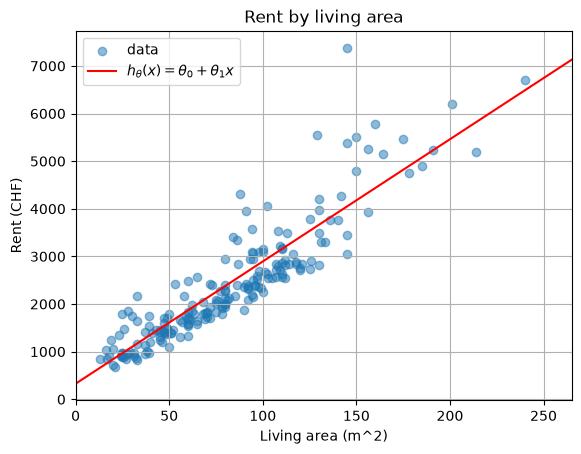

In [41]:
line_on_scatter(X, y, intercept, slope)

In [42]:
print(f'Final cost value {np.mean((intercept + slope * X - y) ** 2) / 2:.4f}')

Final cost value 138963.2776


In [43]:
animate_line_on_scatter(history, X, y, "mini_batch_gradient_descent.gif")

Check that when $B = N$, you fall back on the batch gradient descent solution, and when $B = 1$, you get the behaviour of stochastic gradient descent.

In [44]:
# Your code here
_, _, _ = mini_batch_gradient_descent(X, y, len(X))
_, _, _ = mini_batch_gradient_descent(X, y, 1)

B = N: running batch gradient descent
B = 1: running stochastic gradient descent
Initial random values for theta_0 (y intercept) 4583.3155 and theta_1 (slope) 0.7151
Converged


The cell above shows that we get the correct behavior when $B=N$ and $B=1$

## Exercise 7 - Optional - Multi-variable linear regression

**Hint** For these two exercises, you may need to perform a normalization of the input data, such as min-max rescaling or z-norm.

a) Implement one of the gradient descent algorithm (ex. 3-5) for the multi-variable linear regression assuming $x_1$ being the living area and $x_2$ the square of the living area. Plot the computed curve (second order) on top of the scatter plot of exercise 1. Do you observe a reduction in the loss?

In [45]:
# Your code here
def multi_stochastic_gradient_descent(X, y, verbose=True):
    N, D = X.shape  # D = number of features

    # randomly initialize thetas
    theta_0 = random.uniform(0.0, float(y.max()))             # y intercept
    theta = np.array([random.uniform(-1.0, 1.0) for _ in range(D)])  # one weight per feature

    print(f"Initial random values: theta_0 = {theta_0:.4f}, theta = {np.round(theta, 4)}")

    # Normalize each column independently
    x_mean = X.mean(axis=0)   # shape (D,)
    x_std = X.std(axis=0)     # shape (D,)
    x_norm = (X - x_mean) / x_std

    # Training parameters
    max_iters = 200_000
    check_every = 1000
    tolerance = 1e-3
    prev_loss = None
    alpha = 0.0001

    def to_original_units(theta_0, theta):
        slopes = theta / x_std
        intercept = theta_0 - np.sum(theta * x_mean / x_std)
        return intercept, slopes

    # History used for animations
    history = []  # (iteration, intercept, slopes) in original units
    intercept, slopes = to_original_units(theta_0, theta)
    history.append((0, intercept, slopes))
    record_every = 50

    for it in range(1, max_iters + 1):
        sample_n = random.randrange(0, N)
        x_n = x_norm[sample_n]      # shape (D,)
        y_n = y[sample_n]

        error = (theta_0 + np.dot(theta, x_n)) - y_n
        theta_0 -= alpha * error
        theta -= alpha * error * x_n   # updates all weights at once

        if it % record_every == 0:
            intercept, slopes = to_original_units(theta_0, theta)
            history.append((it, intercept, slopes))

        if it % check_every == 0:
            preds = theta_0 + x_norm @ theta
            loss = np.mean((preds - y) ** 2) / 2
            if verbose:
                print(f"iter {it}: loss = {loss:.2f}, theta_0 = {theta_0:.3f}, theta = {np.round(theta, 3)}")

            if not np.isfinite(loss):
                print("Diverged: try a smaller alpha")
                break
            if prev_loss is not None and abs(prev_loss - loss) < tolerance * prev_loss:
                print("Converged")
                break
            prev_loss = loss

    intercept, slopes = to_original_units(theta_0, theta)
    return history, intercept, slopes

In [46]:
# Feature matrix: x1 = area, x2 = area^2
X_poly = np.column_stack([X, X ** 2])   # shape (N, 2)

history, intercept, slopes = multi_stochastic_gradient_descent(X_poly, y)
theta_0, theta_1, theta_2 = intercept, slopes[0], slopes[1]
print(f"h(x) = {theta_0:.2f} + {theta_1:.3f}*x + {theta_2:.5f}*x^2")

Initial random values: theta_0 = 217.0279, theta = [0.5641 0.5132]
iter 1000: loss = 2502050.12, theta_0 = 419.347, theta = [88.429 82.151]
iter 2000: loss = 2007007.00, theta_0 = 606.848, theta = [174.527 166.856]
iter 3000: loss = 1643967.89, theta_0 = 771.542, theta = [235.659 225.392]
iter 4000: loss = 1349494.86, theta_0 = 922.067, theta = [290.203 277.7  ]
iter 5000: loss = 1100076.19, theta_0 = 1064.683, theta = [344.534 328.177]
iter 6000: loss = 918357.50, theta_0 = 1185.370, theta = [381.981 365.567]
iter 7000: loss = 773315.50, theta_0 = 1298.288, theta = [407.86  387.731]
iter 8000: loss = 647723.33, theta_0 = 1402.842, theta = [440.709 416.524]
iter 9000: loss = 551070.54, theta_0 = 1494.819, theta = [464.829 438.672]
iter 10000: loss = 475137.60, theta_0 = 1577.157, theta = [482.355 453.509]
iter 11000: loss = 411332.85, theta_0 = 1653.288, theta = [500.371 468.859]
iter 12000: loss = 359547.01, theta_0 = 1722.096, theta = [516.67  483.073]
iter 13000: loss = 316941.32, t

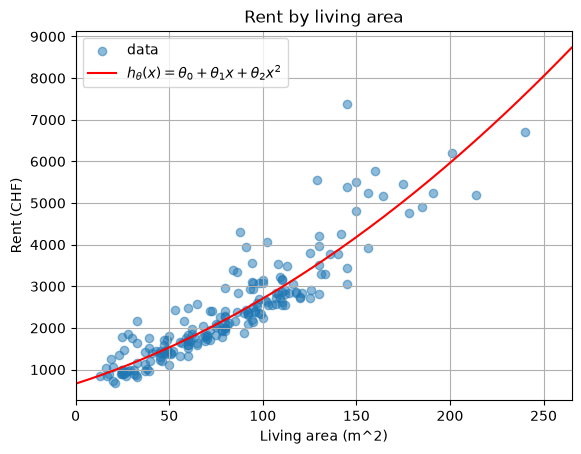

In [47]:
plt.title("Rent by living area")
plt.xlabel("Living area (m^2)")
plt.ylabel("Rent (CHF)")
plt.scatter(X, y, alpha=0.5, label="data")

x_curve = np.linspace(0.0, X.max() + 25, 200)
y_curve = theta_0 + theta_1 * x_curve + theta_2 * x_curve ** 2
plt.plot(x_curve, y_curve, color="red",
        label=r"$h_{\theta}(x) = \theta_0 + \theta_1 x + \theta_2 x^2$")

plt.xlim(0.0, X.max() + 25)
plt.legend()
plt.grid(True)
plt.show()

In [48]:
def animate_curve_on_scatter(history, X, y, name):
    # Split history into proper numeric arrays
    its    = np.array([h[0] for h in history], dtype=float)   # (T,)
    b0s    = np.array([h[1] for h in history], dtype=float)   # (T,)
    slopes_hist = np.array([h[2] for h in history], dtype=float)   # (T, 2)

    # ~150 frames, spaced logarithmically so the fast early movement is visible
    idx = np.unique(np.geomspace(1, len(its), 150).astype(int)) - 1

    x_curve = np.linspace(0.0, X.max() + 25, 200)

    fig, ax = plt.subplots()
    ax.scatter(X, y, alpha=0.5, label="data")

    # Exact quadratic fit as reference (polyfit returns highest degree first)
    c2, c1, c0 = np.polyfit(X, y, 2)
    ax.plot(x_curve, c0 + c1 * x_curve + c2 * x_curve ** 2, "k--", lw=1,
            label="exact fit (polyfit)")

    line, = ax.plot([], [], color="red", lw=2, label=r"$h_{\theta}(x)$")
    text = ax.text(0.97, 0.05, "", transform=ax.transAxes, ha="right")

    ax.set_xlim(0.0, X.max() + 25)
    ax.set_ylim(0, y.max() * 1.1)
    ax.set_title("Rent by living area")
    ax.set_xlabel("Living area (m^2)")
    ax.set_ylabel("Rent (CHF)")
    ax.grid(True)
    ax.legend(loc="upper left")

    def update(frame):
        k = idx[frame]
        y_curve = b0s[k] + slopes_hist[k, 0] * x_curve + slopes_hist[k, 1] * x_curve ** 2
        line.set_data(x_curve, y_curve)
        text.set_text(f"iteration {int(its[k])}")
        return line, text

    anim = FuncAnimation(fig, update, frames=len(idx), interval=50, blit=True)
    plt.close(fig)
    HTML(anim.to_jshtml())
    anim.save(name, writer=PillowWriter(fps=20))

animate_curve_on_scatter(history, X, y, "multi_stoch_gradient_descent.gif")

In [49]:
y_pred = intercept + X_poly @ slopes
final_cost = np.mean((y_pred - y) ** 2) / 2
print(f"Final cost value {final_cost:.4f}")

Final cost value 136666.0746


Our implementation of the univariate stochastic gradient descent has a final cost value of 139332.1485 (this value varies every time the code is run). The multivariate version has a final cost value of 136666.0746 which also changes each time.

After running the code multiple times, it seems like the multivariate version performs slightly better each time.

b) Implement one of the gradient descent algorithm (ex. 3-5) for the multi-variable linear regression assuming $x_1$ being the living area and $x_2$ the number of bedrooms. Do you observe a reduction in the loss?

In [50]:
# Your code here
# Feature matrix: x1 = living area, x2 = nb rooms
X_poly = np.column_stack([X, dataset.nb_rooms.values])   # shape (N, 2)

history, intercept, slopes = multi_stochastic_gradient_descent(X_poly, y)
theta_0, theta_1, theta_2 = intercept, slopes[0], slopes[1]
print(f"h(x) = {theta_0:.2f} + {theta_1:.3f}*area + {theta_2:.3f}*rooms")

Initial random values: theta_0 = 2013.6665, theta = [-0.6518  0.7691]
iter 1000: loss = 627084.28, theta_0 = 2047.726, theta = [101.133  90.739]
iter 2000: loss = 487936.11, theta_0 = 2082.077, theta = [188.297 165.001]
iter 3000: loss = 394639.67, theta_0 = 2108.580, theta = [259.549 224.367]
iter 4000: loss = 328990.70, theta_0 = 2133.164, theta = [319.484 273.694]
iter 5000: loss = 278631.41, theta_0 = 2159.508, theta = [375.51  317.023]
iter 6000: loss = 243004.59, theta_0 = 2183.808, theta = [425.242 352.316]
iter 7000: loss = 224110.78, theta_0 = 2199.679, theta = [457.755 373.637]
iter 8000: loss = 209804.83, theta_0 = 2216.648, theta = [486.902 389.456]
iter 9000: loss = 198358.30, theta_0 = 2234.128, theta = [513.061 405.108]
iter 10000: loss = 191084.35, theta_0 = 2245.100, theta = [534.667 415.329]
iter 11000: loss = 185703.46, theta_0 = 2258.007, theta = [551.351 422.726]
iter 12000: loss = 179738.80, theta_0 = 2272.579, theta = [575.312 430.835]
iter 13000: loss = 176699.2

In [51]:
y_pred = intercept + X_poly @ slopes
final_cost = np.mean((y_pred - y) ** 2) / 2
print(f"Final cost value {final_cost:.4f}")

Final cost value 148005.1650


In this case it seems like the univariate version performs better 139332.1485 vs 148005.1650 final cost value. Running the code notebook multiple times shows the same pattern.
